---

# CSCI 3202, Fall 2024
# Final Project - Checkers

<br> 

### Ananya Nepal

<br> 

In [3]:
# Used for Q-Learning Agent
from collections import defaultdict

# Used to replicate random results
import random
# random.seed(109)

# Used for user playing against AI
from IPython.display import clear_output
import time

# Used to print data
import matplotlib.pyplot as plt



In [4]:
# The default 8x8 board. I will not use this for the project as it would take too long to train the agent
# In the implementation of the game I have created a smaller board with fewer pieces that I will be using
DEFAULT_BOARD=[
                     [0, 1, 0, 1, 0, 1, 0, 1],
                     [1, 0, 1, 0, 1, 0, 1, 0],
                     [0, 1, 0, 1, 0, 1, 0, 1],
                     [0, 0, 0, 0, 0, 0, 0, 0],
                     [0, 0, 0, 0, 0, 0, 0, 0],
                     [2, 0, 2, 0, 2, 0, 2, 0],
                     [0, 2, 0, 2, 0, 2, 0, 2],
                     [2, 0, 2, 0, 2, 0, 2, 0]
                                ]

In [5]:
class Checkers:
    def __init__(self, board=None):
        self.board = [
                     [1, 0, 1, 0, 1],
                     [0, 0, 0, 0, 0],
                     [0, 0, 0, 0, 0],
                     [0, 0, 0, 0, 0],
                     [2, 0, 2, 0, 2]
                                ]
        if board:
            self.board=board
    
        
        self.p1Pieces=[1, 10]
        self.p2Pieces=[2, 20]
        self.current_player = 1
        self.double=False
        self.double_piece=[]
        
        # Size of board
        self.length=5
        self.width=5
        
    # This generates a random move and plays it. 
    def random_move(self):
        end_result=self.end_state()
        if end_result != False:
            return end_result
        #Random for player 1
        if self.current_player == 1:
            valid_pieces={}
            rowLoc=0
            colLoc=0
            for i in self.board:
                colLoc=0
                for j in i:
                    if j in self.p2Pieces or j==0:
                        colLoc+=1
                    else:
                        if j==10:
                            if self.get_valid_moves(rowLoc, colLoc, 1, True, self.double)!={}:
                                valid_pieces[(rowLoc, colLoc)]=self.get_valid_moves(rowLoc, colLoc, 1, True, self.double)
                                colLoc+=1
                            else:
                                colLoc+=1
                                
                     
                        elif j==1:
                            if self.get_valid_moves(rowLoc, colLoc, 1, False, self.double)!={}:
                                valid_pieces[(rowLoc, colLoc)]=self.get_valid_moves(rowLoc, colLoc, 1, False, self.double)
                                colLoc+=1
                            else:
                                colLoc+=1
                rowLoc+=1
            pieceRow, pieceCol=random.choice(list(valid_pieces.keys()))
            moveRow, moveCol=random.choice(list(valid_pieces[(pieceRow, pieceCol)].keys()))
            
            return self.play(pieceRow, pieceCol, moveRow, moveCol)
            
        #Random for player 2    
        else:
            valid_pieces={}
            rowLoc=0
            colLoc=0
            for i in self.board:
                colLoc=0
                for j in i:
                    if j in self.p1Pieces or j==0:
                        colLoc+=1
                    else:
                        if j==20:
                            if self.get_valid_moves(rowLoc, colLoc, 2, True, self.double)!={}:
                                valid_pieces[(rowLoc, colLoc)]=self.get_valid_moves(rowLoc, colLoc, 2, True, self.double)
                                colLoc+=1
                            else:
                                colLoc+=1
                                
                     
                        elif j==2:
                            if self.get_valid_moves(rowLoc, colLoc, 2, False, self.double)!={}:
                                valid_pieces[(rowLoc, colLoc)]=self.get_valid_moves(rowLoc, colLoc, 2, False, self.double)
                                colLoc+=1
                            else:
                                colLoc+=1
                rowLoc+=1
            
            pieceRow, pieceCol=random.choice(list(valid_pieces.keys()))
            moveRow, moveCol=random.choice(list(valid_pieces[(pieceRow, pieceCol)].keys()))
            
            return self.play(pieceRow, pieceCol, moveRow, moveCol)
            
    
    # Printing the board
    def display_board(self):
        counterRow=0
        print("    ", end=" ")
        for i in range(0, self.length):
            print("c{0}".format(i), end="  ")
        print("\n")
        for i in self.board:
            print("r{0}".format(counterRow), end="    ")
            counterRow+=1
            for j in i:
                if j==0:
                    print("-", end="   ")
                else:
                    if j==10 or j==20:
                        print(j, end="  ")
                    else:
                        print(j, end="   ")
                    
            print("\n")
        print("Turn: P{0}".format(self.current_player))
        
    # If the board has no player 1 piece or player 2 piece then it is a win
    # Draws are possible if there are no more valid moves left
    # If game is not in end state return false
    def end_state(self):
        locRow=0
        locCol=0
        p1_counter=0
        p2_counter=0
        p1_stuck=True
        p2_stuck=True
        
        for i in self.board:
            locCol=0
            for j in i:
                if j==1:
                    p1_counter+=1 
                    if self.get_valid_moves(locRow, locCol, 1) != {}:
                        p1_stuck=False
                    
                elif j==2:
                    p2_counter+=1
                    if self.get_valid_moves(locRow, locCol, 2) != {}:
                        p2_stuck=False

                elif j==10:
                    p1_counter+=1 
                    if self.get_valid_moves(locRow, locCol, 1, True) != {}:
                        p1_stuck=False
                    
                elif j==20:
                    p2_counter+=1
                    if self.get_valid_moves(locRow, locCol, 2, True) != {}:
                        p2_stuck=False
                    
                locCol+=1
            locRow+=1
            
            
        if p1_counter==0:
#             print("P2 wins")
            return 2
        if p2_counter==0:
#             print("P1 wins")
            return 1
        
        # If pieces are still up then we need to check if those pieces can move
        if p1_stuck and not p2_stuck:
#             print("P2 wins")
            return 2
        if p2_stuck and not p1_stuck:
#             print("P1 wins")
            return 1
        if p1_stuck and p2_stuck:
#             print("Draw")
            return 3
            
        
        # # # 
        return False
    
    # This is the function to get all valid moves for a given piece
    # Row, Column is the position of the piece
    # Player indicates whose turn it is
    # is_king indicates if the piece is a king
    # is_double indicates if a double jump case has been reached
    def get_valid_moves(self, row, column, player, is_king=False, is_double=False, double=None):
        if double!=None:
            self.double_piece=[double]
        if is_double==True and self.double_piece[0]!=(row, column):
            return {}
        
        if (self.board[row][column]in self.p1Pieces and player==2) or (self.board[row][column] in self.p2Pieces and player==1) or self.board[row][column]==0:
            return {}
        
        final={}
        moves=[(row+1, column+1),
        (row+1, column-1),
        (row-1, column+1),
        (row-1, column-1)]
        
        
        for i in moves:
            row_end=i[0]
            column_end=i[1]
            if row_end not in range(0, self.width) or column_end not in range(0, self.length):
                continue
            
            if not is_king:
                
                #Player 1
                if not row_end>row and player==1:
                    continue
                #Player 2
                elif not row_end<row and player==2:
                    continue
                    
            # If out of bounds  
            if row_end<0 or row_end>self.width-1 or column_end<0 or column_end>self.length-1:
                continue
                
           
            # If player 1
            if player==1:
                # If player 1 piece is blocking
                if self.board[row_end][column_end] not in [0, 2, 20]:
                    continue
                
                # If player 2 piece is blocking
                elif self.board[row_end][column_end] in [2, 20]:
                    if row_end not in range(1,self.width-1) or column_end not in range(1,self.length-1):
                        continue
                    if not is_king:
                        if column_end<column:
                            try:
                                end_state=self.board[row_end+1][column_end-1]
                            except:
                                continue
                            else:
                                if end_state!=0:
                                    continue
                                else:
                                    
                                    final[(row_end+1, column_end-1)]=(row_end, column_end)
                                    continue
                        else:
                            try:
                                end_state=self.board[row_end+1][column_end+1]
                            except:
                                continue
                            else:
                                if end_state!=0:
                                    continue
                                else:
                                    final[(row_end+1, column_end+1)]=(row_end, column_end)
                                    continue
                    # if piece is king
                    if is_king:
                        if column_end<column and row_end>row:
                            try:
                                end_state=self.board[row_end+1][column_end-1]
                            except:
                                continue
                            else:
                                if end_state!=0:
                                    continue
                                else:
                                    final[(row_end+1, column_end-1)]=(row_end, column_end)
                                    continue
                        elif column_end<column and row_end<row:
                            try:
                                end_state=self.board[row_end-1][column_end-1]
                            except:
                                continue
                            else:
                                if end_state!=0:
                                    continue
                                else:
                                    final[(row_end-1, column_end-1)]=(row_end, column_end)
                                    continue
                                    
                        elif column_end>column and row_end>row:
                            try:
                                end_state=self.board[row_end+1][column_end+1]
                            except:
                                continue
                            else:
                                if end_state!=0:
                                    continue
                                else:
                                    final[(row_end+1, column_end+1)]=(row_end, column_end)
                                    continue
                                    
                        elif column_end>column and row_end<row:
                            try:
                                end_state=self.board[row_end-1][column_end+1]
                            except:
                                continue
                            else:
                                if end_state!=0:
                                    continue
                                else:
                                    final[(row_end-1, column_end+1)]=(row_end, column_end)
                                    continue
                         
            if player==2:

                # If player 2 piece is blocking
                if self.board[row_end][column_end] not in [0, 1, 10]:
                    continue

                # If player 1 piece is blocking
                elif self.board[row_end][column_end] in [1, 10]:
                    if row_end not in range(1,self.width-1) or column_end not in range(1,self.length-1):
                        continue
                    if not is_king:
                        if column_end<column:
                            try:
                                end_state=self.board[row_end-1][column_end-1]
                            except:
                                continue
                            else:
                                if end_state!=0:
                                    continue
                                else:
                                    final[(row_end-1, column_end-1)]=(row_end, column_end)
                                    continue
                        else:
                            try:
                                end_state=self.board[row_end-1][column_end+1]
                            except:
                                continue
                            else:
                                if end_state!=0:
                                    continue
                                else:
                                    final[(row_end-1, column_end+1)]=(row_end, column_end)
                                    continue
                    # if piece is king
                    if is_king:
                        if column_end<column and row_end>row:
                            try:
                                end_state=self.board[row_end+1][column_end-1]
                            except:
                                continue
                            else:
                                if end_state!=0:
                                    continue
                                else:
                                    final[(row_end+1, column_end-1)]=(row_end, column_end)
                                    continue
                        elif column_end<column and row_end<row:
                            try:
                                end_state=self.board[row_end-1][column_end-1]
                            except:
                                continue
                            else:
                                if end_state!=0:
                                    continue
                                else:
                                    final[(row_end-1, column_end-1)]=(row_end, column_end)
                                    continue

                        elif column_end>column and row_end>row:
                            try:
                                end_state=self.board[row_end+1][column_end+1]
                            except:
                                continue
                            else:
                                if end_state!=0:
                                    continue
                                else:
                                    final[(row_end+1, column_end+1)]=(row_end, column_end)
                                    continue

                        elif column_end>column and row_end<row:
                            try:
                                end_state=self.board[row_end-1][column_end+1]
                            except:
                                continue
                            else:
                                if end_state!=0:
                                    continue
                                else:
                                    final[(row_end-1, column_end+1)]=(row_end, column_end)
                                    continue

            if is_double==True:                   
                continue
            else:
                final[i]=None
            
        # Final set of moves
        return final
    
        
    
        
    # Rules for play that are implemented:
        # 1. If the piece is a non-king (1, 2) then it can only move "up" the board
        # 2. If the piece is a king (10, 20) then it can move either up or down
        # 3. If the space it wants to jump to is occupied by its own piece then it is invalid move
        # 4. If the space it wants to jump to is not occupied by an enemy piece move it
            # 4a. If the movement jumps over an enemy piece then take the enemy piece
        # 5. If the piece lands at the ending row change it from a non-king to a king
        # 6. If the piece lands in a place that it can take pieces then don't switch turn (allow player to double jump)
            # 6a. Store the piece that can make the double jump and force the player to move that piece only. 

    def play(self, row_start, column_start, row_end, column_end):
        # In case a new board is required
        board_out=self.board
        piece_taken=False
        end_test=self.end_state()
        
        
        # Making sure we are not in end_state
        
        if end_test!=False:
#             print("Game Over")
            return end_test
        
        
        # Check validity of move
        if row_start not in range(0, self.width) or row_end not in range(0,self.length) or column_start not in range(0,self.width) or column_end not in range(0,self.length):
            print("Invalid move")
            return board_out
        
        
        
        moves_with_piece={}
        is_king=board_out[row_start][column_start]==10 or board_out[row_start][column_start]==20
        
        # Cases for move, given that piece may be a king or the current turn is a double move 
        if is_king and self.double:
            moves_with_piece=self.get_valid_moves(row_start, column_start, self.current_player, True, True)
        elif is_king and not self.double:
            moves_with_piece=self.get_valid_moves(row_start, column_start, self.current_player, True, False)
        elif not is_king and self.double:
            moves_with_piece=self.get_valid_moves(row_start, column_start, self.current_player, False, True)
        else:
            moves_with_piece=self.get_valid_moves(row_start, column_start, self.current_player, False, False)
        
        
        
        # If the given play is in valid moves
        if (row_end, column_end) in moves_with_piece:
            
            
            temp=board_out[row_start][column_start]
            board_out[row_start][column_start]=0
            board_out[row_end][column_end]=temp
            
            # Remove enemy piece
            if moves_with_piece[(row_end, column_end)]!=None:
                enemy_row, enemy_column=moves_with_piece[(row_end, column_end)]
                board_out[enemy_row][enemy_column]=0
                piece_taken=True

   
            # Double Jumps
            if piece_taken:
                self.double_piece=[]
                self.double_piece.append((row_end, column_end))
                double={}
                if is_king:
                    double=self.get_valid_moves(row_end, column_end, self.current_player, True, True)
                else:
                    double=self.get_valid_moves(row_end, column_end, self.current_player, False, True)              
                for i in double:
                    if double[i]!=None:
#                         print("Double jump available")
                        self.double=True
                        return board_out
                    

            # Promote to king if end row reached
            if row_end == self.width-1 and self.current_player == 1:
                board_out[row_end][column_end]=10
            if row_end == 0 and self.current_player == 2:
                board_out[row_end][column_end]=20
            
            # Reseting variables and changing turn
            self.double_piece=[]
            self.double=False
            if self.current_player==1: 
                self.current_player=2 
            else:
                self.current_player=1    
        
            return board_out
        else:
            # Player inputted an invalid move.
            print("row start:{0}, column start:{1}, row end:{2}, column end:{3}".format(row_start, column_start, row_end, column_end))
            print("Valid moves: {0}".format(moves_with_piece))
            print("Not valid play")
            return False

In [6]:
# This QLearningAgent code has been modified from the AIMA-python code repository. 
# I utilized the reinforcement_learning.py page in order to generate this code. 
RMAX=1000
class QLearningAgent(Checkers):
    def __init__(self, Ne, Rplus, alpha=None):

        self.gamma = 0.7
        self.terminals = None #Terminal states
        self.all_act = None #Actions in given state
        
        
        
        self.Ne = Ne  # iteration limit in exploration function
        self.Rplus = Rplus  # large value to assign before iteration limit
        self.Q = defaultdict(float)
        self.Nsa = defaultdict(float)
        self.s = None #Previous State
        self.a = None
        self.r = None 

        if alpha:
            self.alpha = alpha
        else:
            self.alpha = lambda n: 1. / (1 + n)  # udacity video

    # Copied from checkers game
    def is_terminal(self, board):
        if board==None:
            return False
        locRow=0
        locCol=0
        p1_counter=0
        p2_counter=0
        p1_stuck=True
        p2_stuck=True
        game=Checkers(board)
        for i in board:
            locCol=0
            for j in i:
                if j==1:
                    p1_counter+=1 
                    if game.get_valid_moves(locRow, locCol, 1) != {}:
                        p1_stuck=False
                    
                elif j==2:
                    p2_counter+=1
                    if game.get_valid_moves(locRow, locCol, 2) != {}:
                        p2_stuck=False

                elif j==10:
                    p1_counter+=1 
                    if game.get_valid_moves(locRow, locCol, 1, True) != {}:
                        p1_stuck=False
                    
                elif j==20:
                    p2_counter+=1
                    if game.get_valid_moves(locRow, locCol, 2, True) != {}:
                        p2_stuck=False
                    
                locCol+=1
            locRow+=1
            
            
        if p1_counter==0:
#             print("P2 wins")
            return 2
        if p2_counter==0:
#             print("P1 wins")
            return 1
        
        # If pieces are still up then we need to check if those pieces can move
        if p1_stuck and not p2_stuck:
#             print("P2 wins")
            return 2
        if p2_stuck and not p1_stuck:
#             print("P1 wins")
            return 1
        if p1_stuck and p2_stuck:
#             print("Draw")
            return 3
            
        
        # # # 
        return False
    

    # Copied from Checkers class
    # For now coding AI as player 2       
    def get_all_moves(self, board):
        valid_pieces={}
        moves=[]
        rowLoc=0
        colLoc=0
        for i in board:
            colLoc=0
            for j in i:
                if j in [10, 1] or j==0:
                    colLoc+=1
                else:
                    if j==20:
                        if Checkers(board).get_valid_moves(rowLoc, colLoc, 2, True, False)!={}:
                            valid_pieces[(rowLoc, colLoc)]=Checkers(board).get_valid_moves(rowLoc, colLoc, 2, True, False)
                            colLoc+=1
                        else:
                            colLoc+=1


                    elif j==2:
                        if Checkers(board).get_valid_moves(rowLoc, colLoc, 2, False, False)!={}:
                            valid_pieces[(rowLoc, colLoc)]=Checkers(board).get_valid_moves(rowLoc, colLoc, 2, False, False)
                            colLoc+=1
                        else:
                            colLoc+=1
            rowLoc+=1
        for i in valid_pieces:
            for j in valid_pieces[i]:
                row_start, col_start=i
                row_end, col_end=j
                moves.append((row_start, col_start, row_end, col_end))
        return moves
                
                
    

    def f(self, u, n):
        """Exploration function. Returns fixed Rplus until
        agent has visited state, action a Ne number of times.
        Same as ADP agent in book."""
       
        if n < self.Ne:
            return self.Rplus
        else:
            return u

    def actions_in_state(self, state):
        """Return actions possible in given state.
        Useful for max and argmax."""
        if self.is_terminal(state):
            return [None]
        else:
            return self.get_all_moves(state)

    def __call__(self, percept, double=None, draw=False):
        # How I plan on storing Q data: state, action, double move. This should capture all of the data that I need 
        s1, r1 = self.update_state(percept, double, draw) # Current State and reward 
        Q, Nsa, s, a, r = self.Q, self.Nsa, self.s, self.a, self.r # Previous state, action, and reward
        alpha, gamma, terminals = self.alpha, self.gamma, self.terminals
        actions_in_state = self.get_all_moves
#         print(f"Previous state: {s}")
#         print(f"Current state: {s1}")
        # Convert type of board to hashable
        s1_=None
        s_=None
        if s1!=None:
            s1_ =tuple(tuple(i) for i in s1)
        if s!=None:
            s_ = tuple(tuple(i) for i in s)
            
        
        
        if self.is_terminal(s1)!=False or draw==True:
            Q[s_, None] = r
            return
        
        elif s is not None:
            # Exploration
            Nsa[s_, a] += 1

            if double != None:
                # We are setting the value of the previous state and action we took by looking at current states and future actions
                Q[s_, a] += alpha(Nsa[s_, a]) * (r + gamma * max(Q[s1_, a1]
                                                           for a1 in double) - Q[s_, a])
            else:
                Q[s_, a] += alpha(Nsa[s_, a]) * (r + gamma * max(Q[s1_, a1]
                                                           for a1 in actions_in_state(s1_)) - Q[s_, a])
        if self.is_terminal(s)!=False:
            self.s = self.a = self.r = None
        else:
            # Set previous to current for next iteration.
            # This may not work
            self.s, self.r = s1_, r1
            if double!= None:
                self.a = max(double, key=lambda a1: self.f(Q[s1_, a1], Nsa[s1_, a1]))
            else:
                self.a = max(actions_in_state(s1_), key=lambda a1: self.f(Q[s1_, a1], Nsa[s1_, a1]))

        return self.a

    def update_state(self, board, double=False, draw=False):
        """To be overridden in most cases. The default case
        assumes the percept to be of type (state, reward)."""
        # Instead of getting reward when calling like in the book, I have created a function to get reward
        if draw:
            return (board, -RMAX)
        if double!=None:
            return (board, self.reward(board, True, double))
        return (board, self.reward(board, False))
    
    # What I have right now:
        # If the game is in an end_state and player 2 won then give max reward
        # If the game is in an end_state and player 1 won then given max penalty
        # If the game is not in an end_state then check what each piece can do
            # If the piece is stuck then take away some reward value
            # If the piece is not stuck then check if it is near any pieces
                # Since this is not checking future states, any pieces nearby may take so count those as negative
                # Increase/Decrease the value if it is a king piece
    def reward(self, board, double=False, piece=None):
        # Assuming that AI is player 2
        game=Checkers()
        game.board=board
        if game.end_state() == 2:
            return RMAX
        if game.end_state() == 1:
            return -RMAX
        if double==True:
            piece=(piece[0][0], piece[0][1])

        # If the AI was able to complete a double jump then we want to give the maximum reward
        if double==True:
            return RMAX
        
        reward=0
        rowLoc=0
        colLoc=0
        for i in board:
            colLoc=0
            for j in i:
                if j==1:
                    result=game.get_valid_moves(rowLoc, colLoc, 1)
                    # Indicates that this piece cannot take anything in this state
                    if result.values()==None:
                        reward-=1
                    # Indicates that there exists a piece that could be taken in next turn. However, AI may take this piece so don't want to punish severly
                    else:
                        reward-=3
                elif j==10:
                    result=game.get_valid_moves(rowLoc, colLoc, 1, True)
                    # Indicates that this piece cannot take anything in this state. Still not good that P1 has a king
                    if result.values()==None:
                        reward-=1
                    else:
                        reward-=4
                elif j==2:
                    result=game.get_valid_moves(rowLoc, colLoc, 1)
                    if result.values()==None:
                        reward-=1
                    else:
                        reward+=2
                elif j==20:
                    result=game.get_valid_moves(rowLoc, colLoc, 1, True)
                    if result.values()==None:
                        reward-=1
                    else:
                        reward+=3
                    reward+=3
                colLoc+=1
            rowLoc+=1
        return reward

In [7]:
# Setting up the environment for the Q-Learning AI to play in
def alpha(v): 
    return 1/(1+v)
q=QLearningAgent(10, RMAX, alpha)
double=False
counter=0
valid_move=[]

# For data collection and analysis
num_1_wins=0
num_2_wins=0
num_draws=0

def draws(D):
    Dcount=0
    counter=0
    rate=[]
    for i in D:
        if counter==1000:
            rate.append(Dcount/1000)
            counter=0
            Dcount=0
        if i==3:
            Dcount+=1
        counter+=1
    return rate

def win_rate(W):
    Wcount=0
    counter=0
    rate=[]
    for i in W:
        if counter==1000:
            rate.append(Wcount/1000)
            counter=0
            Wcount=0
        if i==2:
            Wcount+=1
        counter+=1
    return rate

## Training Q-Learning AI Against Random Move Player

In [8]:
# This cell is used to show the Q-Learning AI against a random player for many matches. This cell also trains the AI
num_1_wins=0
num_2_wins=0
num_draws=0
game_num=0
Wins=[]

# Number of games to be played. More games leads to better performance
for i in range(10000):
    valid=None
    valid_move=[]
    game_num+=1
    test_game=Checkers()
    q.s=None
    q.a=None
    q.r=None

    counter=0

    while test_game.end_state()==False:
        counter+=1
        # If we have played 1000 turns it is safe to assume that no winner will emerge
        # This counts the game as a draw
        if counter==500:
            break
        if test_game.current_player==2:
            if valid_move!=[]:
                row_start, col_start, row_end, col_end=q(test_game.board, valid_move)
            else:
                row_start, col_start, row_end, col_end=q(test_game.board)

            valid=test_game.play(row_start, col_start, row_end, col_end)
        

            if test_game.double:
                piece=test_game.double_piece

                is_king= test_game.board[piece[0][0]][piece[0][1]]==20
                move = test_game.get_valid_moves(piece[0][0], piece[0][1], 2, is_king, True)
                valid_move=[]
                for i in move:
                    if move[i]==None:
                        continue
                    else:
                        valid_move.append((piece[0][0], piece[0][1], i[0], i[1]))
            if not valid:
                s1_ =tuple(tuple(i) for i in test_game.board)
                print("An error has occured in game: {0}".format(game_num))
                print("This is finish board: ")
                test_game.display_board()
                break
                
        else:
            valid_move=[]
            test_game.random_move()  
    winner=test_game.end_state()
    if valid==False:
        break
    if winner==1:
        q(test_game.board)
        Wins.append(1)
        num_1_wins+=1
    elif winner==2:
        q(test_game.board)
        num_2_wins+=1
        Wins.append(2)
    else:
        q(test_game.board, None, True)
        Wins.append(3)
        num_draws+=1
    if game_num%10000==0:
        print(f"{game_num} Games Completed", flush=True)

10000 Games Completed


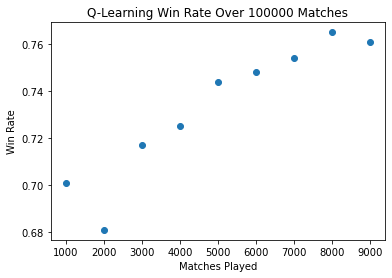

In [9]:
# This prints out the win rate per 1000 matches over all of the matches. The win rate should improve over time
plt.scatter(range(1000, game_num, 1000), win_rate(Wins))
plt.title("Q-Learning Win Rate Over 100000 Matches")
plt.ylabel("Win Rate")
plt.xlabel("Matches Played");

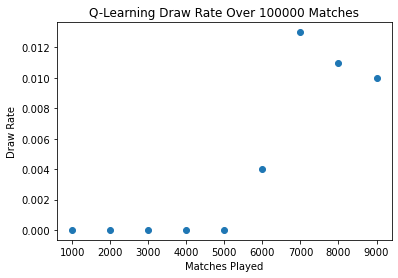

In [10]:
plt.scatter(range(1000, game_num, 1000), draws(Wins))
plt.title("Q-Learning Draw Rate Over 100000 Matches")
plt.ylabel("Draw Rate")
plt.xlabel("Matches Played");

In [11]:
print(f"In {game_num} Games: \n The random player won: {num_1_wins} \n Q-Learning AI player won: {num_2_wins} \n both drawed: {num_draws} \n AI has a win rate of {(num_2_wins/(num_1_wins+num_2_wins+num_draws))*100}%")

In 10000 Games: 
 The random player won: 2598 
 Q-Learning AI player won: 7354 
 both drawed: 48 
 AI has a win rate of 73.54%


## Random VS. Random

In [13]:
# Random vs. Random also printing the results
test_random=Checkers()
wins=[]
num_1win=0
num_2win=0
num_draw=0
num_games=10000
counter=0
winner=0
game_test=0
game_over=False
turn=0


for i in range(num_games):
    counter+=1
    test_random=Checkers()
    while 1:
        winner=test_random.random_move()
        if winner in [1, 2]:
#             print("P{0} Won".format(winner))
            break
        elif winner==3:
#             print("Draw")
            break
    if winner==1:
        num_1win+=1
        wins.append(1)
    elif winner==2:
        num_2win+=1
        wins.append(2)
    else:
        num_draw+=1
        wins.append(3)
    if counter % 10000 == 0:
        print(f"{counter} games completed")

10000 games completed


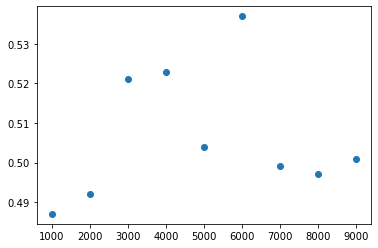

In [14]:
plt.scatter(range(1000, num_games, 1000), win_rate(wins));

In [15]:
print("In {3} Games: \n Random player 1 won: {0} \n Random player 2 won: {1} \n Both drawed: {2}".format(num_1win, num_2win, num_draw, num_games))

In 10000 Games: 
 Random player 1 won: 4929 
 Random player 2 won: 5071 
 Both drawed: 0


## Playing Against AI / Random / Another Player

In [19]:
## Playing against Q-Learning AI
turn=0
valid=None
valid_move=[]
game_num+=1
test_game=Checkers()
q.s=None
q.a=None
q.r=None
test_game.display_board()
while test_game.end_state()==False:
    if test_game.current_player==1:
        start_row=input("Choose your piece's starting row: ")
        start_col=input("Choose your piece's starting column: ")
        end_row=input("Choose your piece's ending row: ")
        end_col=input("Choose your piece's ending column: ")
        clear_output()
        test_game.play(int(start_row), int(start_col), int(end_row), int(end_col))
        test_game.display_board()
        turn+=1
        valid_move=[]
    else:
        print("AI Thinking")
        time.sleep(3)
        clear_output()
        if valid_move!=[]:
                row_start, col_start, row_end, col_end=q(test_game.board, valid_move)
        else:
                row_start, col_start, row_end, col_end=q(test_game.board)

        valid=test_game.play(row_start, col_start, row_end, col_end)

        if test_game.double:
            piece=test_game.double_piece

            is_king= test_game.board[piece[0][0]][piece[0][1]]==10
            move = test_game.get_valid_moves(piece[0][0], piece[0][1], 2, is_king, True)
            valid_move=[]
            for i in move:
                if move[i]==None:
                    continue
                else:
                    valid_move.append((piece[0][0], piece[0][1], i[0], i[1]))
        
        # If everything works properly it should never enter here. I have still put this up to catch any errors
        if not valid:
            s1_ =tuple(tuple(i) for i in test_game.board)
            print("An error has occured in game: ")
            print(game_num)
            print("This is finish board: ")
            test_game.display_board()
            break
        
        test_game.display_board()
        turn+=1
if test_game.end_state()==3:
    print("Game Draw")
else:
    print(f"Player {test_game.end_state()} Won")


# Playing with random, uncomment clear calls for a prettier print
# while not game_over:
#     if test.current_player==1:
#         start_row=input("Choose your piece's starting row: ")
#         start_col=input("Choose your piece's starting column: ")
#         end_row=input("Choose your piece's ending row: ")
#         end_col=input("Choose your piece's ending column: ")
# #         clear_output()
#         game_test=test.play(int(start_row), int(start_col), int(end_row), int(end_col))
#         test.display_board()
#         turn+=1
#     else:
#         print("Random thinking")
# #         time.sleep(3)
# #         clear_output()
#         game_test=test.random_move()
#         test.display_board()
#         turn+=1
#     if game_test==False:
#         game_over=True



# Playing with no AI
# while not game_over:
#     start_row=input("Choose your piece's starting row: ")
#     start_col=input("Choose your piece's starting column: ")
#     end_row=input("Choose your piece's ending row: ")
#     end_col=input("Choose your piece's ending column: ")
#     clear_output()
#     game_test=test.play(int(start_row), int(start_col), int(end_row), int(end_col))
#     if game_test==False:
#         game_over=True
#     test.display_board()
    



     c0  c1  c2  c3  c4  

r0    -   -   -   -   -   

r1    -   -   -   -   -   

r2    -   -   -   -   -   

r3    -   -   -   10  -   

r4    -   -   10  -   -   

Turn: P2
Player 1 Won


# Intermediate Result
What I have done:
I have created a working checkers game that can take inputs for player 1 and player 2. I have currently programmed it so that man pieces can only move and jump forward while kings can move and jump in any direction
I have also created a player that can play random moves.
I have also been able to play the random player against another random player and get the results 
I have also implemented the Q-Learning agent from the book and adjusted it to take in the values of my game in order to evaluate it. This Q-Learning agent can play against the random player. I also have some results for this

What I have noticed so far:
For boards that are larger than 4x4 each random player wins about half of the time. For a small board such as 4x4 player 1 wins about 60% of the time. If I train on a board that is larger than 4x4 I will expect my Q-Learning agent to win more than half of the games, if it is a 4x4 then I will expect a win rate that is greater than 60% if it plays as player 1.  
I have also noticed that the AI plays more matches that end in a draw. I think this is related to my current reward function which is not very complex right now. 
I have also created a function that checks the win rate over a certain amount of games, this is so that I can see if the win rate improves with the matches played indicating that my AI is learning
I started building the Q-Learning agent with the assumption that it would be playing as player 1, however, after I noticed that player 1 has an advantage in the 4x4 board I decided to make the AI play as player 2. This should be a better indicator of how good the AI is doing since there is no default advantage when playing as player 1

Intermediate Results:
On a 4x4 board the AI wins about 50% of the time while the random player wins about 25% of the time. This is an improvement from the random vs. random. If it was like the random vs. random the AI would win only 40% while the random player would win 60%. There is some biasing towards draws that I cannot understand. It could be that at some point keeping the draw is better than winning but I do not think that this is the case. It is possible that if I give the AI more turns to try and win it could improve its win rate but I do not think that it would help. I have also noticed that there is no direct indicator of learning from the AI. The win rates seem to flucuate randomly which indicates that the AI is not necessarily learning. 

What I need to do now:
I think the performance of my AI will improve the greatest if I improve my reward function and make it more complex. I may also need to look at how the Q-Learning agent is evaluating the boards as it may not be doing it in the way that I think it is. I think that there is some issue with capturing the end states that I will need to look into. 

# Project Writeup

### What my code does:

I have recreated a smaller game of checkers and utilized Q-Learning in order to create an AI that can play the game better than a player that does random moves. The AI is trained on multiple matches of checkers against a player that makes random moves. After the AI has trained against the random player it is possible for the AI to play against the user. In order to create the game I only utilized the numpy random library to generate random moves. I created the  Q-Learning AI using the AIMA Q-Learning code as a template. This can be found in the AIMA code base in the file reinforcement_learning.py. The other libraries that I have used are only for printing data or printing the game which are IPython.display to get prettier prints and matplotlib.pyplot to print training data.

### Test results:

In order to check if my Q-Learning AI has worked I am testing if it does better than a random player vs. random player. To do this I have my Q-Learning AI play 100000 matches against a player making random moves. I then store the wins and generate the win rate. If the algorithm is working then I expect to see the win rate improve with more matches played and I expect the overall number of wins to be greater than a random player vs. random player. 

After playing 100000 matches we can see that the win rate does improve with more matches played. This indicates that the AI is learning and improving. Printing the results we see that the AI has a win rate that is usually in the range of 75-85%. This is an improvement from the random player which has a win rate of about 50%. Based on the data the AI does achieve the goal of learning and improving over the random player. 

I have noticed that with more matches played the number of games the AI draws also increases. I believe that this is due to my current reward function and parameters. With more testing and a more complex reward function I believe that the win rate and draw rate would improve. 

I have selected 100000 games since it shows how the AI can improve in a smaller amount of training time. I have run a test in which the AI played 1000000 games which took significantly more time than training on 100000 games and didn't result in too much improvement. If I was training on a full sized board with all of the pieces it would most likely take more than 1000000 games to reach the same results. 

### Example:

In the above cells the AI is trained and can be played against. After training the AI it is possible to play against it by inputting moves. In my current implementation I have directly coded the AI to be player 2 as it is more proficient in showing improvements on smaller game boards. I have previously set the AI to player 1 as well and given more time I would have added the ability to choose which player the AI plays as.

In order to play against the AI, run all cells and input values where prompted. 


### What I learned:

When I started this project I had originally intended to try generating a game tree and using alpha-beta pruning to get the best values. I decided not to do this because generating future game states was very difficult for my current implementation and because Q-Learning was a better method for this game. Q-Learning is better because I do not need to consider future states and can rely on past and current states which are very easy to access. The down side of this is that the AI will need to play many matches in order to show improvements. By using Q-Learning I have learned how it works and how altering certain values can change the performance of my AI. 

&emsp; Since I did implement a Q-Learning AI I had to study how the algorithm worked and how I could modify those values and parameters to accept the information of my game. The aspect of the code that I found most difficult to understand was which states were being stored as the previous state and which state was being stored as the current state. After understanding this it was easier to see what values were being taken in and how they were being manipulated. Along with this I spent a lot of time considering what values the paramters such as the alpha function or gamma value should be. While these don't have as significant of an impact as the reward function, I found that it was still important to find the most optimal values in order to achieve my goals. I would still like to improve my code more and so I believe that the most important aspect I should look at is my reward function and paramters. 
